        # Lesson 7.3 · The Honest Scoreboard
        ### Metrics, baselines, walk-forward validation, rolling origins and forecast horizons

        | | |
        |---|---|
        | ⏱️ **Time** | about 90 minutes |
        | 📚 **Before you start** | Lessons 7.1 and 7.2 |
        | 🧪 **Format** | lesson → worked examples → exercises with hints → recap |

        ## 🎯 What you will be able to do after this notebook
        - Compute and interpret **MAE, RMSE, MAPE, sMAPE and MASE**: and know when MAPE is dangerous
- Explain, with an experiment, why **shuffling** a time series produces misleading scores
- Build **naive, seasonal-naive and drift baselines** every model must beat
- Implement **walk-forward (rolling-origin)** evaluation and read error **by forecast horizon**

> 🌾 **The story so far.** Before we build a single fancy model, we agree on the scoreboard. A student once showed me a model with 98% accuracy on tomato prices. It had been shuffled. *Let's make sure that student is never you.*

In [1]:
import sys, pathlib, warnings
# Find the course folder (works no matter where Jupyter was started)
ROOT = next(p for p in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents] if (p / "src" / "agrilab.py").exists())
sys.path.insert(0, str(ROOT / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import agrilab as ag          # our helper library: src/agrilab.py

from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split, TimeSeriesSplit
warnings.filterwarnings("ignore")   # (after imports: statsmodels re-enables its own warnings when imported)
ag.setup_plots()
ag.set_seed(42)
print("Setup complete. Course folder:", ROOT.name)

Setup complete. Course folder: course


## 1 · Anatomy of a forecast

Standing at **forecast origin** $t$ (the last day whose data we're allowed to use), we predict $h$ steps ahead:

$$\hat y_{t+h \mid t}$$

read "the forecast of $y_{t+h}$ made at time $t$". Three words to keep straight:

| Term | Meaning |
|---|---|
| **Origin** $t$ | the moment we forecast *from* |
| **Horizon** $h$ | how far ahead (1 week? 13 weeks?) |
| **Error** $e_{t+h} = y_{t+h} - \hat y_{t+h\mid t}$ | actual minus forecast |

Our workhorse series: weekly tomato price, Central market.

In [2]:
y = ag.price_series("tomato", "Central", "W")
print(len(y), "weeks:", y.index[0].date(), "→", y.index[-1].date())

523 weeks: 2015-01-04 → 2025-01-05


## 2 · The metrics, one by one

Let errors be $e_i = y_i - \hat y_i$ over $n$ forecasts.

| Metric | Formula | In words | Watch out for |
|---|---|---|---|
| **MAE** | $\frac1n\sum \lvert e_i\rvert$ | average miss, in price units | easy to explain to farmers ✅ |
| **RMSE** | $\sqrt{\frac1n\sum e_i^2}$ | like MAE but **big misses hurt more** | dominated by outliers/shocks |
| **MAPE** | $\frac{100}{n}\sum \left\lvert \frac{e_i}{y_i}\right\rvert$ | average % miss | **explodes if $y_i \approx 0$**; favours under-forecasts |
| **sMAPE** | $\frac{100}{n}\sum \frac{\lvert e_i\rvert}{(\lvert y_i\rvert+\lvert\hat y_i\rvert)/2}$ | MAPE with a symmetric denominator | still odd near zero, but bounded |
| **MASE** | $\frac{\text{MAE}}{\text{MAE of in-sample (seasonal) naive}}$ | skill vs naive; **< 1 beats naive** | needs the training data |

A tiny example to build intuition: *one big miss changes the story*:

In [3]:
actual = np.array([100, 102, 101, 103, 100.0])
good   = np.array([101, 101, 102, 102, 101.0])      # always off by 1
spiky  = np.array([100, 102, 101, 103, 105.0])      # exact, except for a single miss of 5
for name, f in [("always off by 1", good), ("perfect then one miss of 5", spiky)]:
    print(f"{name:28s} MAE={ag.mae(actual, f):.2f}  RMSE={ag.rmse(actual, f):.2f}  MAPE={ag.mape(actual, f):.2f}%")

always off by 1              MAE=1.00  RMSE=1.00  MAPE=0.99%
perfect then one miss of 5   MAE=1.00  RMSE=2.24  MAPE=1.00%


Both have similar MAE (1.0 vs 1.0) but RMSE tells them apart (1.0 vs 2.24): **RMSE punishes a few big errors**.
For agriculture that's often what you want: one disastrous price spike matters more than many small wiggles.

### The MAPE trap
Daily rainfall is zero on dry days. What does MAPE do there?

In [4]:
rain = ag.load_weather()["rainfall_mm"].to_numpy()[:30]
pred = np.full_like(rain, rain.mean())
print("zeros in actuals:", int((rain == 0).sum()), "of", len(rain))
try:
    print(ag.mape(rain, pred))
except ValueError as e:
    print("MAPE refuses ->", e)
print(f"sMAPE = {ag.smape(rain, pred):.1f}%   |  MAE = {ag.mae(rain, pred):.2f} mm   |  RMSE = {ag.rmse(rain, pred):.2f} mm")

zeros in actuals: 26 of 30
MAPE refuses -> MAPE undefined: some actual values are ~0. Use MAE/RMSE/sMAPE/MASE instead.
sMAPE = 187.9%   |  MAE = 0.61 mm   |  RMSE = 1.36 mm


> ⚠️ **Common pitfall.** MAPE with a zero (or near-zero) actual divides by ~0 and returns `inf` or a meaningless giant number. Prices are never zero, so MAPE is fine for *our* project, but for rainfall, volumes of a rarely-traded crop, or intermittent demand, use MAE, RMSE, sMAPE, or MASE.

---
### 🧩 Exercise 1: Write the metrics yourself  ⭐

Implement `my_mape(y, yhat)` and `my_smape(y, yhat)` returning **percentages**. `my_mape` must return `np.nan`
(not crash, not `inf`) if any actual value has `abs(y) < 1e-8`. Then compute both for the arrays below into
`res_a` and `res_b` (a tuple `(mape, smape)` each).

<details><summary>💡 Hint 1: gentle nudge</summary>

Convert inputs with `np.asarray(..., dtype=float)` first.

</details>

<details><summary>💡 Hint 2: bigger nudge</summary>

MAPE: `np.mean(np.abs((y - yhat) / y)) * 100`, guarded by `if np.any(np.abs(y) < 1e-8): return np.nan`.

</details>

<details><summary>💡 Hint 3: almost the answer</summary>

sMAPE: denominator `(np.abs(y) + np.abs(yhat)) / 2`. Compare with `ag.smape`.

</details>

*Write your answer in the next cell, then run the check cell below it. Stuck after the hints? The full solution is in `solutions/`.*

In [ ]:
def my_mape(y, yhat):
    return None

def my_smape(y, yhat):
    return None

a_y, a_p = [100, 120, 80], [110, 100, 90]
b_y, b_p = [0, 5, 10], [1, 4, 12]
res_a = None
res_b = None

In [ ]:
try:
    ag.check("MAPE of case A is right", np.isclose(res_a[0], ag.mape(a_y, a_p)))
    ag.check("sMAPE of case A is right", np.isclose(res_a[1], ag.smape(a_y, a_p)))
    ag.check("MAPE of case B (has a zero) is NaN, not inf", np.isnan(res_b[0]))
    ag.check("sMAPE of case B is finite", np.isfinite(res_b[1]))
except Exception as _e:
    print('\u23f3 Not ready yet: finish the exercise cell above, then re-run this check.  (' + type(_e).__name__ + ': ' + str(_e)[:90] + ')')

---
## 3 · Why you must never shuffle a time series

The classic `train_test_split(X, y, shuffle=True)` puts *future* rows in the training set. A model trained on March and May
is asked to "forecast" April: that's **interpolation**, not forecasting. Let's catch the cheat in the act with one experiment:
the *same* model, the *same* features, two different splits.

In [7]:
feat = ag.make_ts_features(y, lags=(1, 2, 3, 4, 52), roll_windows=(4, 13)).dropna()
X, t = feat.drop(columns="y"), feat["y"]

# (a) the WRONG way: random 80/20
Xtr, Xte, ytr, yte = train_test_split(X, t, test_size=0.2, shuffle=True, random_state=0)
rf_shuf = RandomForestRegressor(300, random_state=0, n_jobs=-1).fit(Xtr, ytr)
mae_shuffled = ag.mae(yte, rf_shuf.predict(Xte))

# (b) the RIGHT way: train on the past, test on the final 20 %
cut = int(len(feat) * 0.8)
rf_chrono = RandomForestRegressor(300, random_state=0, n_jobs=-1).fit(X.iloc[:cut], t.iloc[:cut])
mae_chrono = ag.mae(t.iloc[cut:], rf_chrono.predict(X.iloc[cut:]))
mae_naive = ag.mae(t.iloc[cut:], X["lag_1"].iloc[cut:])

print(f"Shuffled split MAE      : {mae_shuffled:6.2f}   <- looks wonderful... and is a lie")
print(f"Chronological split MAE : {mae_chrono:6.2f}   <- the honest number")
print(f"Naive (last week) MAE   : {mae_naive:6.2f}")

Shuffled split MAE      :   4.74   <- looks wonderful... and is a lie
Chronological split MAE :   9.24   <- the honest number
Naive (last week) MAE   :   5.69


> 🤔 **Pause and think.** Why is the chronological error so much larger? (Hint: think about what a random forest can and cannot do outside the price range it saw in training.)
>
> <details><summary>Click to reveal the answer</summary>
>
> Prices trend upward. In a chronological test the model must predict levels *higher than anything it was trained on*, and tree models cannot extrapolate beyond their training range: they predict the largest value they've seen. A shuffled test set is surrounded by training points with similar levels, so it never has to extrapolate. **The shuffled score hides the model's biggest weakness.** (Lesson 7.6 shows how to fix it by modelling *changes* instead of levels.)
>
> </details>

---
### 🧩 Exercise 2: Leak audit  ⭐

Below are eight ways someone computed a feature for forecasting daily price `y` (target is `y_t`).
Decide which ones **leak future information**. Put the letters of the leaky ones in a Python **set** called `leaky`.

| | Feature code |
|---|---|
| a | `y.shift(7)` |
| b | `y.rolling(7).mean()` |
| c | `y.shift(1).rolling(7).mean()` |
| d | `y.rolling(7, center=True).mean()` |
| e | `y.shift(-1)` |
| f | `y.expanding().mean().shift(1)` |
| g | `StandardScaler().fit_transform(y)` fitted on the **entire** series, then split |
| h | `y.index.month` |

<details><summary>💡 Hint 1: gentle nudge</summary>

Ask of each: *'Does the value in row t depend on y_t or anything after t?'*

</details>

<details><summary>💡 Hint 2: bigger nudge</summary>

Row t of `y.rolling(7).mean()` averages y_(t-6)…y_t. Does that include the very thing we're predicting?

</details>

<details><summary>💡 Hint 3: almost the answer</summary>

Scaling with statistics of the *whole* series leaks mean & std of the test period into training: a subtle leak. The calendar month is known in advance, so it is safe.

</details>

*Write your answer in the next cell, then run the check cell below it. Stuck after the hints? The full solution is in `solutions/`.*

In [ ]:
leaky = set()   # e.g. {"a", "b"}

In [ ]:
try:
    ag.check("you found all four leaks, and no false alarms", leaky == {"b", "d", "e", "g"},
             "b includes y_t itself; d and e look forward; g uses statistics from the test period")
except Exception as _e:
    print('\u23f3 Not ready yet: finish the exercise cell above, then re-run this check.  (' + type(_e).__name__ + ': ' + str(_e)[:90] + ')')

---
## 4 · Baselines: the bar to clear

> *"If your model can't beat 'tomorrow = today', go home."*: every forecaster, eventually

| Baseline | Rule | When it shines |
|---|---|---|
| **Mean** | predict the historical average | basically never, for trending data |
| **Naive** | last value | short horizons, random-walk-like series |
| **Seasonal naive** | value from one season ago | strongly seasonal series, longer horizons |
| **Drift** | last value + average historical slope | steadily trending series |

They're one-liners: in `ag` and implemented below so you can see how little code they take.

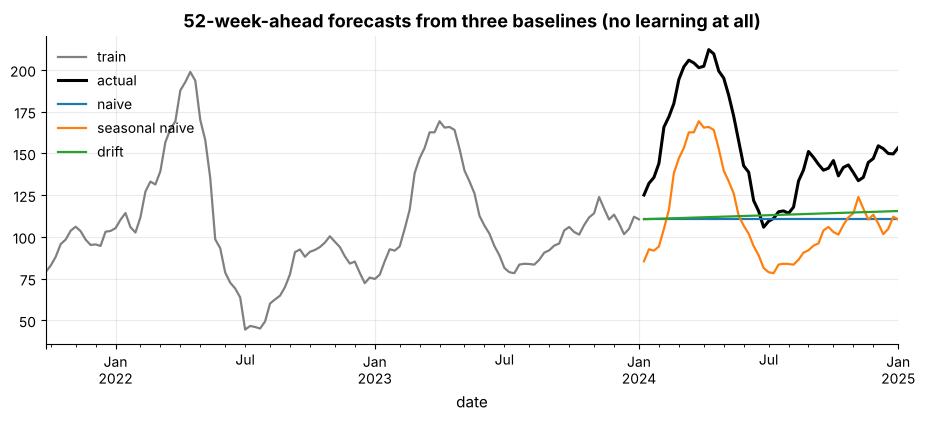

In [10]:
def naive(train, h):          return np.repeat(train.iloc[-1], h)
def seasonal_naive(train, h, m=52):
    last = train.iloc[-m:].to_numpy();  return np.array([last[i % m] for i in range(h)])
def drift(train, h):
    slope = (train.iloc[-1] - train.iloc[0]) / (len(train) - 1);  return train.iloc[-1] + slope * np.arange(1, h + 1)

train, test = y.iloc[:-52], y.iloc[-52:]                       # hold out the final year
fig, ax = plt.subplots(figsize=(11, 4))
train.iloc[-120:].plot(ax=ax, color="gray", label="train")
test.plot(ax=ax, color="black", lw=2.2, label="actual")
for nm, f in [("naive", naive), ("seasonal naive", seasonal_naive), ("drift", drift)]:
    pd.Series(f(train, 52), index=test.index).plot(ax=ax, label=nm)
ax.legend(); ax.set_title("52-week-ahead forecasts from three baselines (no learning at all)"); plt.show()

This is a **single** train/test split with a 52-step horizon: a quick look, not a robust verdict. One test year might be
lucky or unlucky. That brings us to the main event.

---
## 5 · Walk-forward validation (rolling-origin evaluation)

Imagine you are really forecasting for the cooperative, every week, for years. Each Monday you:
1. take **all data up to now**, 2. fit the model, 3. forecast the next *h* weeks, 4. wait and see.

Walk-forward evaluation **replays that history**: move the origin forward, refit, forecast, record, repeat.
It gives *many* forecast errors instead of one, each made with honestly-available information.

| Variant | Training window | Use when |
|---|---|---|
| **Expanding** | grows with each step | more history always helps |
| **Sliding (rolling)** | fixed length | regime changes; old data is stale; fair compute cost |

Let's draw the folds so the idea sticks:

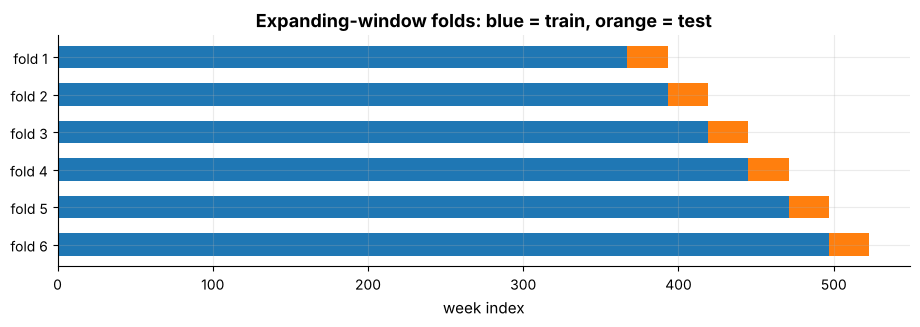

In [11]:
tscv = TimeSeriesSplit(n_splits=6, test_size=26)
fig, ax = plt.subplots(figsize=(11, 3))
for i, (tr, te) in enumerate(tscv.split(y)):
    ax.barh(i, len(tr), left=tr[0], color="tab:blue", height=.6)
    ax.barh(i, len(te), left=te[0], color="tab:orange", height=.6)
ax.set(yticks=range(6), yticklabels=[f"fold {i+1}" for i in range(6)], xlabel="week index", title="Expanding-window folds: blue = train, orange = test"); ax.invert_yaxis(); plt.show()

Our helper `ag.walk_forward(y, fit_predict, initial, horizon, step, expanding)` does exactly this for **any** model.
A "model" is just a function `fit_predict(train, h) -> h forecasts`. Here are the baselines on 13-week horizons:

In [12]:
models = {"naive": ag.naive_forecast, "seasonal naive": ag.seasonal_naive_forecast, "drift": ag.drift_forecast, "mean": ag.mean_forecast}
wf = {name: ag.walk_forward(y, f, initial=260, horizon=13, step=2) for name, f in models.items()}
print("origins evaluated:", wf["naive"].origin_date.nunique(), "| forecasts per model:", len(wf["naive"]))
ag.score_table(wf, y_train=y.iloc[:260])

origins evaluated: 126 | forecasts per model: 1638


,MAE,RMSE,MAPE,MASE
seasonal naive,21.947,26.291,19.059,5.825
naive,28.218,39.085,27.841,7.489
drift,28.415,39.565,28.197,7.542
mean,33.880,45.533,26.712,8.992


> 📏 **Reading MASE here.** MASE divides by the in-sample *one-step* naive error. We're scoring horizons up to 13 weeks, which are
> naturally harder than one step, so every value is above 1. Don't panic: use MASE to **compare models with each other** at the same horizon,
> or compute it with `m=52` against the seasonal-naive scale when you want a "skill vs seasonal naive" reading.

### Error by horizon: the most important plot in forecasting

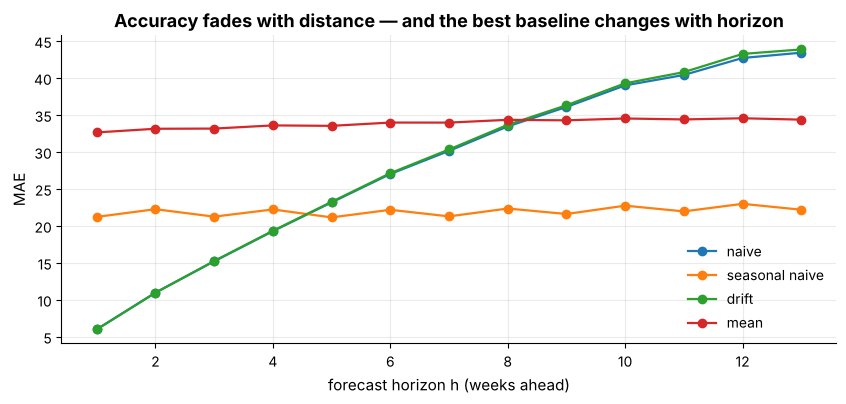

In [13]:
by_h = pd.DataFrame({n: r.groupby("h").apply(lambda d: ag.mae(d.actual, d.forecast)) for n, r in wf.items()})
ax = by_h.plot(marker="o", figsize=(10, 4)); ax.set(xlabel="forecast horizon h (weeks ahead)", ylabel="MAE", title="Accuracy fades with distance: and the best baseline changes with horizon")
plt.show()

Read it carefully:
- **Naive** is excellent at $h=1$ (persistence!) but its error grows steadily with $h$.
- **Seasonal naive** is mediocre at $h=1$ but *flat*: it's as wrong at week 13 as at week 1.
- The lines **cross**. There is no "best baseline", only "best baseline for this horizon". The same will be true of *your* models, which is why we always report error **by horizon**.

> 🌾 **Decision link.** "Should we store tomatoes for six weeks?" is an $h = 6$ question. Judge models at $h = 6$, not at $h = 1$.

### The hidden cost of not refitting
In real deployment the model gets *re-fitted* as new data arrives. A walk-forward loop that re-fits every origin is the faithful simulation:
and it's **expensive** for ARIMA/XGBoost, so you'll often use `step=4` (refit monthly) as a compromise. Always state your choice in the report.

---
### 🧩 Exercise 3: Three baselines, one scoreboard  ⭐⭐

Using the single split `train, test = y.iloc[:-52], y.iloc[-52:]`:
1. Produce 52-step forecasts from `naive`, `seasonal_naive` and `drift` (functions above) → dict `fc` keyed by name.
2. Compute the **MAE** of each against `test` → dict `scores`.
3. Set `best_baseline` to the name with the lowest MAE.
4. Compute `mase_best`: MASE of the best baseline using `ag.mase(test, fc[best], train, m=52)`
   (scale by the *seasonal* naive error with m=52).

<details><summary>💡 Hint 1: gentle nudge</summary>

`fc = {'naive': naive(train, 52), 'seasonal naive': seasonal_naive(train, 52), 'drift': drift(train, 52)}`

</details>

<details><summary>💡 Hint 2: bigger nudge</summary>

`scores = {k: ag.mae(test, v) for k, v in fc.items()}`

</details>

<details><summary>💡 Hint 3: almost the answer</summary>

`best_baseline = min(scores, key=scores.get)`; then `ag.mase(test, fc[best_baseline], train, m=52)`.

</details>

*Write your answer in the next cell, then run the check cell below it. Stuck after the hints? The full solution is in `solutions/`.*

In [ ]:
fc = {}
scores = {}
best_baseline = None
mase_best = None

In [ ]:
try:
    ag.check("three forecasts of length 52", all(len(v) == 52 for v in fc.values()) and len(fc) == 3)
    ag.check("scores are MAEs", len(fc) == 3 and set(scores) == set(fc) and all(np.isclose(scores[k], ag.mae(test, fc[k])) for k in fc))
    ag.check("best_baseline is the arg-min", best_baseline == min(scores, key=scores.get))
    ag.check("mase_best is computed with m=52", np.isclose(mase_best, ag.mase(test, fc[best_baseline], train, m=52)))
except Exception as _e:
    print('\u23f3 Not ready yet: finish the exercise cell above, then re-run this check.  (' + type(_e).__name__ + ': ' + str(_e)[:90] + ')')

---
### 🧩 Exercise 4: Write your own walk-forward loop  ⭐⭐⭐

Without calling `ag.walk_forward`, evaluate the **naive** forecaster with an **expanding window**:
first training window = 260 weeks, horizon `H = 4`, origin moves 1 week at a time.
Collect, for every (origin, h), the pair (actual, forecast). Then compute `rmse_by_h`: a NumPy array with the **RMSE for each h = 1..4**.

<details><summary>💡 Hint 1: gentle nudge</summary>

Loop `for end in range(260, len(y) - H + 1):`: `end` is the first index *not* in training: `train = y.iloc[:end]`.

</details>

<details><summary>💡 Hint 2: bigger nudge</summary>

The forecast made at this origin is `naive(train, H)`; the actuals are `y.iloc[end:end+H]`.

</details>

<details><summary>💡 Hint 3: almost the answer</summary>

Store errors in a list per horizon: `errs[h-1].append(actual[h-1] - fc[h-1])`. Afterwards `rmse_by_h = np.array([np.sqrt(np.mean(np.square(e))) for e in errs])`.

</details>

*Write your answer in the next cell, then run the check cell below it. Stuck after the hints? The full solution is in `solutions/`.*

In [ ]:
H = 4
errs = [[] for _ in range(H)]
# for end in range(...):
#     ...
rmse_by_h = None

In [ ]:
try:
    ref = ag.walk_forward(y, ag.naive_forecast, initial=260, horizon=4, step=1)
    ref_rmse = ref.groupby("h").apply(lambda d: ag.rmse(d.actual, d.forecast)).to_numpy()
    ag.check("one RMSE per horizon", rmse_by_h is not None and len(rmse_by_h) == 4)
    ag.check("matches ag.walk_forward", rmse_by_h is not None and np.allclose(rmse_by_h, ref_rmse), "check the loop bounds: the last origin must still have H future points")
    ag.check("error grows with horizon (naive)", rmse_by_h is not None and np.all(np.diff(rmse_by_h) > 0))
except Exception as _e:
    print('\u23f3 Not ready yet: finish the exercise cell above, then re-run this check.  (' + type(_e).__name__ + ': ' + str(_e)[:90] + ')')

---
## 6 · A reporting template you can reuse

Whenever you report a forecasting result, answer **six** questions. Print this and tape it to your monitor:

1. **What** series, what frequency, what period?
2. **What horizon(s)?** (report error *by horizon*)
3. **What validation?** walk-forward, expanding or sliding, how many origins, refit frequency
4. **Which baselines?** at least naive and seasonal naive
5. **Which metrics?** MAE + RMSE (+ MASE for skill), MAPE only if actuals are far from zero
6. **What did it cost?** training time, complexity: a model that is 1% better but 100× slower may not be better

## 🎓 Mini-quiz
1. Walk-forward uses 200 origins and a horizon of 4. How many forecast errors does it produce per model?
2. A model has MASE = 1.3. Good or bad?
3. You evaluate only at h = 1 and report "beats naive by 30 %". The cooperative cares about h = 8. What's wrong?

<details><summary>Answers</summary>

1. 200 × 4 = **800** (one per origin per horizon).
2. **Worse than naive** (MASE > 1 means its error is 30 % *larger* than the in-sample naive error).
3. Skill at $h=1$ says little about $h=8$; baselines and models *change rank* with horizon. Evaluate at the horizon that drives the decision.
</details>

        ---
        ## 🧾 Recap
        - Metrics: **MAE** (interpretable), **RMSE** (punishes big misses), **MAPE/sMAPE** (percent; mind the zeros), **MASE** (< 1 beats naive).
- Shuffling a time series leaks the future and flatters the score: in our experiment the honest error was nearly **double** the shuffled one.
- Baselines (naive, seasonal naive, drift) are the minimum bar; the best one depends on the horizon.
- **Walk-forward** evaluation replays real forecasting; use expanding or sliding windows and say which.
- Always report **error by horizon**, with the metric that matches the decision.

**Next up:** Lesson 7.4: smoothing methods: moving average, exponential smoothing, Holt and Holt-Winters.